# Lab 5: Machine Learning for Intelligent Decision Making

## 1. Introduction to Machine Learning

Machine Learning (ML) is a branch of Artificial Intelligence that allows computers to learn patterns from data and make predictions without explicitly programming every decision.

For example, a machine learning model can analyze students' CGPA, aptitude scores, and backlogs to predict whether they are likely to get placed.

### Types of Machine Learning

| Type                   | Description                          | Example                      |
| ---------------------- | ------------------------------------ | ---------------------------- |
| Supervised Learning    | Learns from labelled data            | Student placement prediction |
| Unsupervised Learning  | Finds patterns in unlabelled data    | Customer grouping            |
| Reinforcement Learning | Learns through rewards and penalties | Game-playing AI              |

## 2. Introduction to Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm used for classification and regression.

It makes decisions using a tree-like structure of conditions.

For example:

```
             CGPA >= 7?
              /     \
            Yes      No
             |        |
        Aptitude>=70  Not Placed
          /    \
        Yes     No
         |       |
      Placed  Not Placed
```

### Important components

- Root Node: The starting point of the decision tree.
- Decision Node: A node that checks a condition.
- Branch: Represents the result of a condition.
- Leaf Node: Represents the final prediction.

### Advantages

- Easy to understand and visualize.
- Handles numerical and categorical problems after suitable preprocessing.
- Requires relatively little preprocessing.
- Can model non-linear decision boundaries.

### Limitations

- Can overfit training data.
- Small changes in data may produce a different tree.
- Deep trees can become difficult to interpret.


# Practical 1: Train the First Decision Tree Classifier

We'll use a small student dataset to predict placement status.

In [1]:
# 1. Import libraries
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [2]:
# 2. Create the dataset
data = {
    "CGPA": [8.5, 7.2, 6.5, 9.0, 5.8,
             8.0, 7.8, 6.0, 9.2, 7.0],
    "Aptitude": [85, 70, 60, 92, 55,
                 80, 75, 50, 95, 65],
    "Backlogs": [0, 1, 2, 0, 3,
                 0, 1, 2, 0, 1],
    "Placed": ["Yes", "Yes", "No", "Yes", "No",
               "Yes", "Yes", "No", "Yes", "No"]
}

df = pd.DataFrame(data)

print(df)

   CGPA  Aptitude  Backlogs Placed
0   8.5        85         0    Yes
1   7.2        70         1    Yes
2   6.5        60         2     No
3   9.0        92         0    Yes
4   5.8        55         3     No
5   8.0        80         0    Yes
6   7.8        75         1    Yes
7   6.0        50         2     No
8   9.2        95         0    Yes
9   7.0        65         1     No


In [4]:
# 3. Create feature matrix and target

X = df[["CGPA", "Aptitude", "Backlogs"]]
y = df["Placed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8
Testing records: 2


In [5]:
# 4. Train the model and make predictions

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Actual Values:", list(y_test))
print("Predicted Values:", list(predictions))

print(
    "Accuracy:",
    accuracy_score(y_test, predictions) * 100,
    "%"
)

Actual Values: ['No', 'Yes']
Predicted Values: ['No', 'Yes']
Accuracy: 100.0 %


# Practical 2: Disease Prediction Using Decision Tree Classifier

In this practical, we'll build a Decision Tree model to classify breast tumour samples as Malignant or Benign using the Scikit-learn Breast Cancer dataset.

This practical also covers model evaluation, confusion matrix, precision, recall, F1-score, and classification report.

## Aim

To implement a Decision Tree Classification model using a medical dataset and evaluate its prediction performance.

## Theory

Disease Prediction uses machine learning algorithms to identify patterns in medical data and predict a possible disease category.

For this practical, we'll use Scikit-learn's built-in Breast Cancer Wisconsin dataset.

It contains:

- 569 samples.
- 30 numerical input features.
- Two target classes: Malignant and Benign.

Decision Tree classification process:

1. Load the medical dataset.
2. Separate input features and target labels.
3. Split data into training and testing sets.
4. Train the Decision Tree model.
5. Predict the target classes.
6. Evaluate model performance.



In [6]:
# 1. Import libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [7]:
# 2. Load the dataset

# Load Breast Cancer dataset
cancer = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Add target column
df["Diagnosis"] = cancer.target

print("Dataset Shape:", df.shape)

print("\nFirst Five Records:")
print(df.head())

print("\nTarget Classes:")
print(cancer.target_names)

Dataset Shape: (569, 31)

First Five Records:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture 

In [8]:
# 3. Prepare features and target

# Separate input features and target
X = df.drop("Diagnosis", axis=1)
y = df["Diagnosis"]

print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Matrix Shape: (569, 30)
Target Shape: (569,)


In [9]:
# 4. Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 455
Testing Records: 114


In [10]:
# 5. Train the Decision Tree model\

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Make predictions
predictions = model.predict(X_test)

print("Model Training Completed!")
print("Predictions:", predictions[:10])

Model Training Completed!
Predictions: [0 1 0 1 0 1 1 0 0 0]


In [11]:
# 6. Evaluate model accuracy

accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 93.86 %


Confusion Matrix:
[[39  3]
 [ 4 68]]


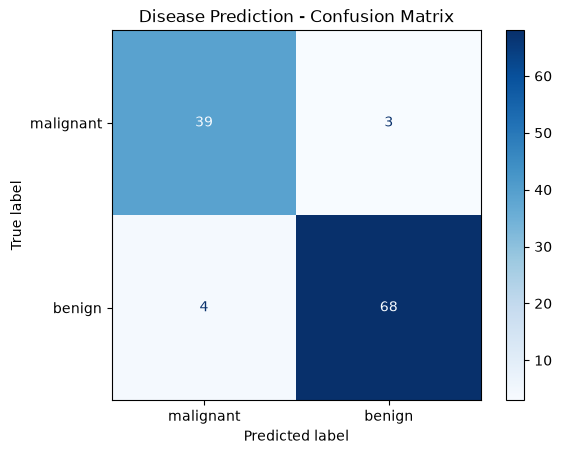

In [12]:
# 7. Generate Confusion Matrix

cm = confusion_matrix(y_test, predictions)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=cancer.target_names
)

display.plot(cmap="Blues")
plt.title("Disease Prediction - Confusion Matrix")
plt.show()

In [13]:
# 8. Classification Report

report = classification_report(
    y_test,
    predictions,
    target_names=cancer.target_names
)

print("Classification Report:\n")
print(report)

Classification Report:

              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



# Practical 3: Loan Approval Prediction Using Decision Tree Classifier

In this practical, we'll develop a machine learning model that predicts whether a loan application should be Approved or Rejected based on applicant information.

## Aim

To implement a Decision Tree Classification model for predicting loan approval using applicant details and evaluate its performance.

## Theory

Loan approval prediction is a classification problem in which a machine learning model analyzes applicant information and predicts the loan decision.

Some important input features are:

- Income
- Credit score
- Loan amount
- Employment status
- Previous loan history

Working process:

1. Create and load the loan dataset.
2. Separate input features and target.
3. Convert categorical data into numerical format.
4. Split data into training and testing sets.
5. Train the Decision Tree model.
6. Predict loan approval.
7. Evaluate the model.


In [14]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [15]:
data = {
    "Income": [
        50000, 30000, 80000, 25000, 90000,
        45000, 70000, 20000, 65000, 35000,
        85000, 40000, 75000, 28000, 95000,
        55000, 32000, 78000, 22000, 60000
    ],

    "CreditScore": [
        750, 600, 800, 550, 820,
        700, 780, 500, 760, 620,
        810, 680, 790, 580, 830,
        740, 610, 770, 520, 730
    ],

    "LoanAmount": [
        200000, 150000, 300000, 100000, 250000,
        180000, 220000, 120000, 200000, 160000,
        280000, 170000, 240000, 130000, 260000,
        190000, 140000, 230000, 110000, 200000
    ],

    "Employment": [
        "Yes", "No", "Yes", "No", "Yes",
        "Yes", "Yes", "No", "Yes", "No",
        "Yes", "Yes", "Yes", "No", "Yes",
        "Yes", "No", "Yes", "No", "Yes"
    ],

    "LoanHistory": [
        "Good", "Poor", "Good", "Poor", "Good",
        "Good", "Good", "Poor", "Good", "Poor",
        "Good", "Poor", "Good", "Poor", "Good",
        "Good", "Poor", "Good", "Poor", "Good"
    ],

    "Approved": [
        "Yes", "No", "Yes", "No", "Yes",
        "Yes", "Yes", "No", "Yes", "No",
        "Yes", "No", "Yes", "No", "Yes",
        "Yes", "No", "Yes", "No", "Yes"
    ]
}

loan_df = pd.DataFrame(data)

print("Loan Dataset:")
print(loan_df.head())

print("\nDataset Shape:", loan_df.shape)
print("\nApproval Distribution:")
print(loan_df["Approved"].value_counts())

Loan Dataset:
   Income  CreditScore  LoanAmount Employment LoanHistory Approved
0   50000          750      200000        Yes        Good      Yes
1   30000          600      150000         No        Poor       No
2   80000          800      300000        Yes        Good      Yes
3   25000          550      100000         No        Poor       No
4   90000          820      250000        Yes        Good      Yes

Dataset Shape: (20, 6)

Approval Distribution:
Approved
Yes    12
No      8
Name: count, dtype: int64


In [16]:
X = loan_df.drop("Approved", axis=1)
y = loan_df["Approved"]

# Convert categorical features into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoded Feature Matrix:")
print(X.head())

print("\nFeature Columns:")
print(list(X.columns))

Encoded Feature Matrix:
   Income  CreditScore  LoanAmount  Employment_Yes  LoanHistory_Poor
0   50000          750      200000               1                 0
1   30000          600      150000               0                 1
2   80000          800      300000               1                 0
3   25000          550      100000               0                 1
4   90000          820      250000               1                 0

Feature Columns:
['Income', 'CreditScore', 'LoanAmount', 'Employment_Yes', 'LoanHistory_Poor']


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 16
Testing Records: 4


In [18]:
loan_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

loan_model.fit(X_train, y_train)

print("Loan Prediction Model Trained Successfully!")

Loan Prediction Model Trained Successfully!


In [19]:
loan_predictions = loan_model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": loan_predictions
})

print("Loan Prediction Results:")
print(results)

Loan Prediction Results:
  Actual Predicted
0     No        No
1     No        No
2    Yes       Yes
3    Yes       Yes


In [20]:
accuracy = accuracy_score(y_test, loan_predictions)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 100.0 %


Confusion Matrix:
[[2 0]
 [0 2]]


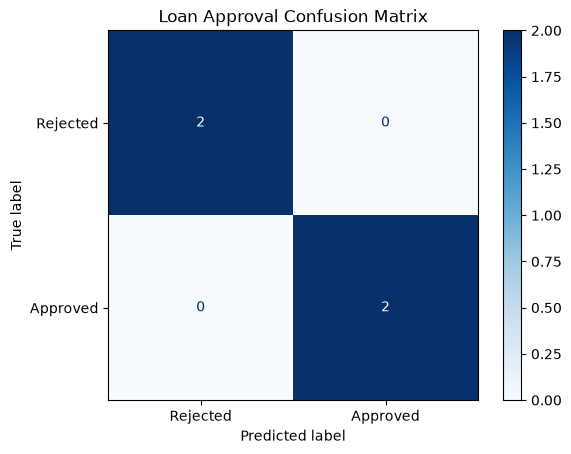

In [21]:
cm = confusion_matrix(
    y_test,
    loan_predictions,
    labels=["No", "Yes"]
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
)

disp.plot(cmap="Blues")
plt.title("Loan Approval Confusion Matrix")
plt.show()

In [22]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        loan_predictions,
        zero_division=0
    )
)

Classification Report:

              precision    recall  f1-score   support

          No       1.00      1.00      1.00         2
         Yes       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



# Practical 4: Decision Tree Visualization

In this practical, we'll visualize a trained Decision Tree Classifier to understand how it makes predictions through conditions and branches.

## Aim

To visualize the structure of a Decision Tree Classifier using Scikit-learn and Matplotlib.

## Theory

A Decision Tree represents decisions in a tree-like structure.

It contains:

- Root Node: Starting point of the decision process.
- Decision Nodes: Conditions used to divide data.
- Branches: Outcomes of those conditions.
- Leaf Nodes: Final predicted classes.

For example:

```
          Credit Score >= 700?
             /          \
           Yes           No
            |             |
       Loan Approved   Loan Rejected
```

Scikit-learn provides the `plot_tree()` function to visualize a trained Decision Tree.



In [24]:
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

In [25]:
# Prepare features and target
X = loan_df.drop("Approved", axis=1)
y = loan_df["Approved"]

# Encode categorical features
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Decision Tree
visual_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

visual_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


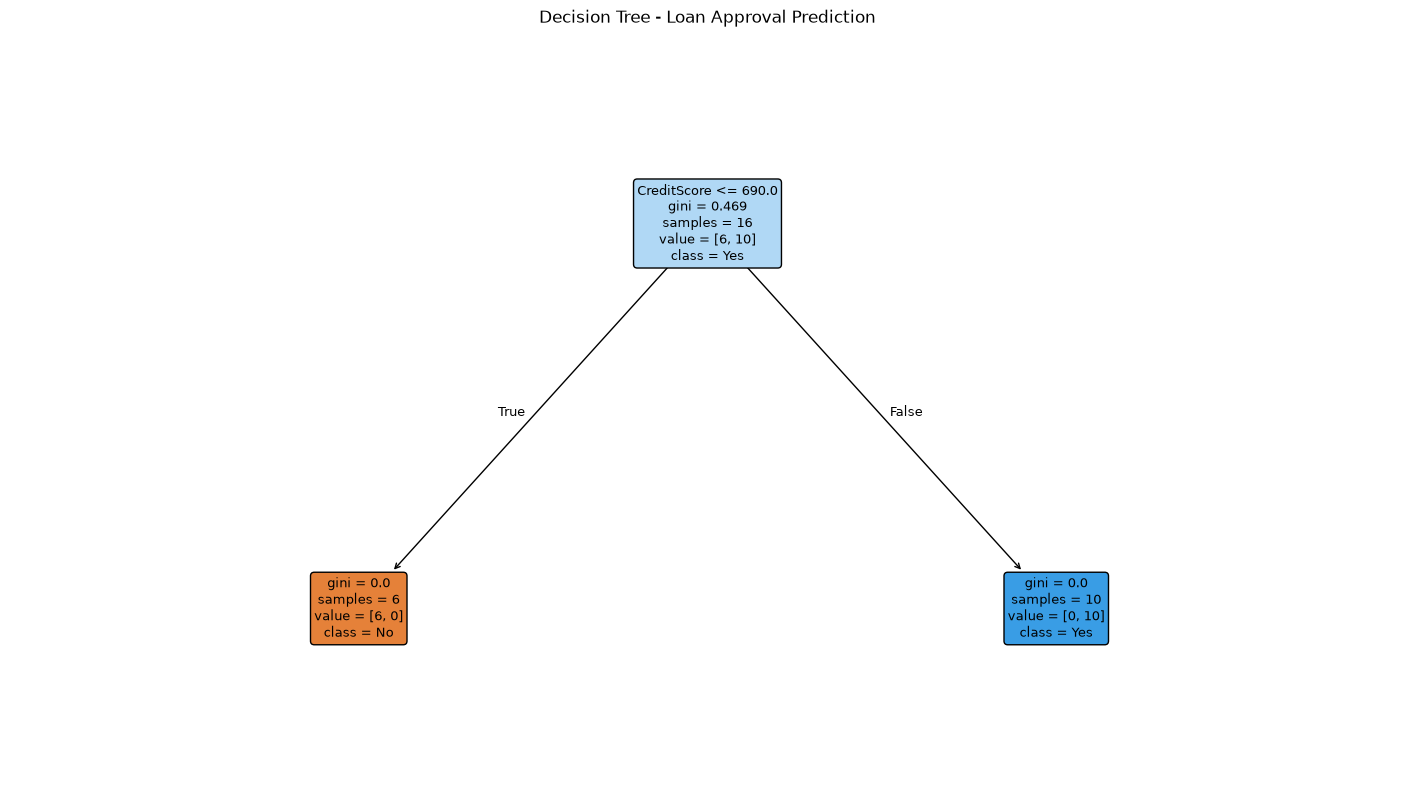

In [26]:
plt.figure(figsize=(18, 10))

plot_tree(
    visual_model,
    feature_names=X.columns,
    class_names=visual_model.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree - Loan Approval Prediction")
plt.savefig(
    "outputs/DecisionTreeVisualization.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()